In [9]:
import yfinance as yf
import pandas as pd
data = yf.download("AAPL",start="2023-01-01",end="2023-12-31")




[*********************100%***********************]  1 of 1 completed


In [7]:
pip install yfinance

  Using cached yfinance-1.7.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached curl_cffi-0.16.3-cp310-abi3-win_amd64.whl.metadata (17 kB)
  Using cached multitasking-0.0.13-py3-none-any.whl.metadata (16 kB)
  Using cached peewee-4.5.3-py3-none-any.whl.metadata (10 kB)
Using cached yfinance-1.7.0-py3-none-any.whl (149 kB)
Using cached curl_cffi-0.16.3-cp310-abi3-win_amd64.whl (2.0 MB)
Using cached multitasking-0.0.13-py3-none-any.whl (16 kB)
Using cached peewee-4.5.3-py3-none-any.whl (194 kB)
  Attempting uninstall: cffi
    Found existing installation: cffi 1.17.1
    Uninstalling cffi-1.17.1:
      Successfully uninstalled cffi-1.17.1
Note: you may need to restart the kernel to use updated packages.


In [11]:
data

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2023-01-03,122.876732,128.604489,121.992513,127.995367,112117500
2023-01-04,124.144119,126.403789,122.886567,124.664824,89113600
2023-01-05,122.827621,125.529397,122.572186,124.900621,80962700
2023-01-06,127.346962,128.005211,122.699912,123.800274,87754700
2023-01-09,127.867668,131.070510,127.612233,128.182064,70790800
...,...,...,...,...,...
2023-12-22,191.268143,193.056339,190.645726,192.829099,37149600
2023-12-26,190.724747,191.554625,190.507395,191.277999,28919300


In [13]:
data.to_csv("AAPL.csv")

[*********************100%***********************]  1 of 1 completed


====== Apple Stock Market Data ======
Price            Close        High         Low        Open     Volume
Date                                                                 
2023-01-03  122.876740  128.604497  121.992521  127.995375  112117500
2023-01-04  124.144119  126.403789  122.886567  124.664824   89113600
2023-01-05  122.827606  125.529381  122.572171  124.900605   80962700
2023-01-06  127.346962  128.005211  122.699912  123.800274   87754700
2023-01-09  127.867661  131.070502  127.612225  128.182056   70790800
====== Dataset Information ======
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 250 entries, 2023-01-03 to 2023-12-29
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   250 non-null    float64
 1   High    250 non-null    float64
 2   Low     250 non-null    float64
 3   Open    250 non-null    float64
 4   Volume  250 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.7 KB
None


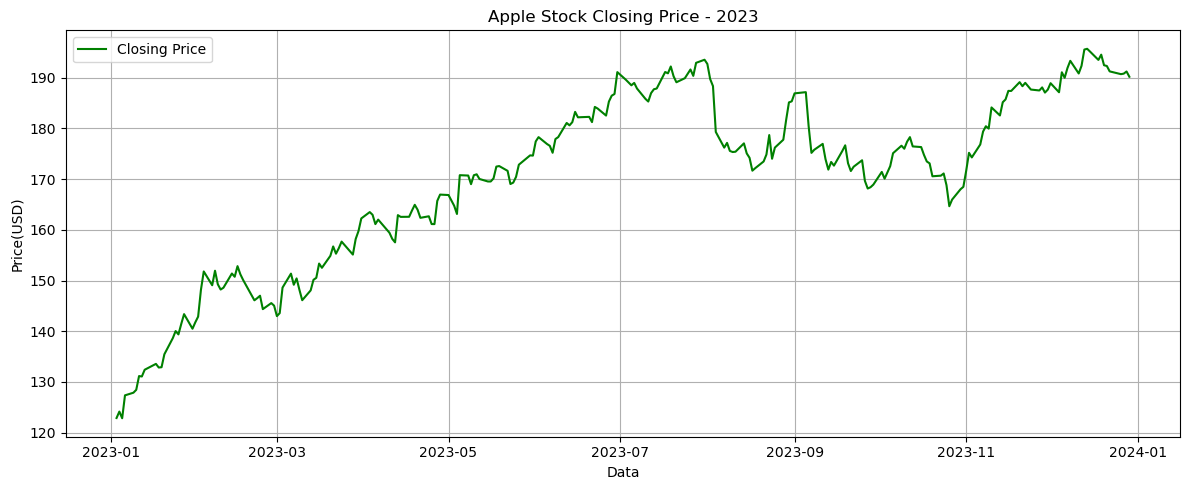

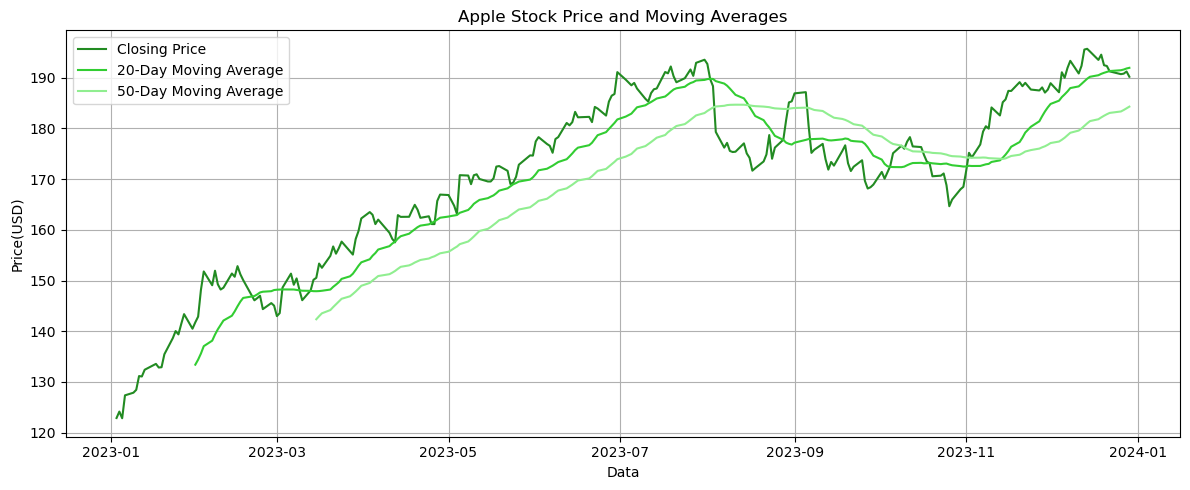

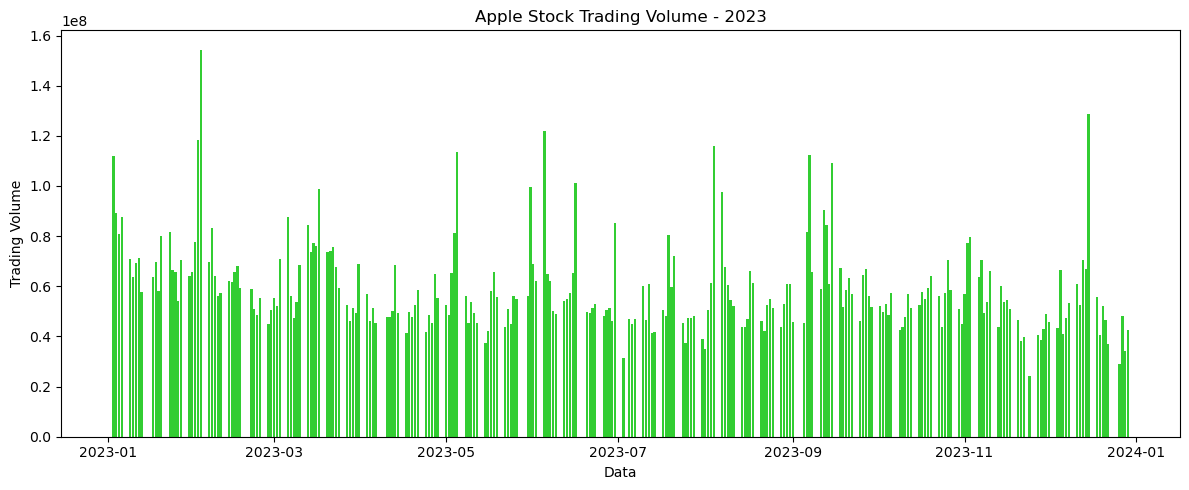

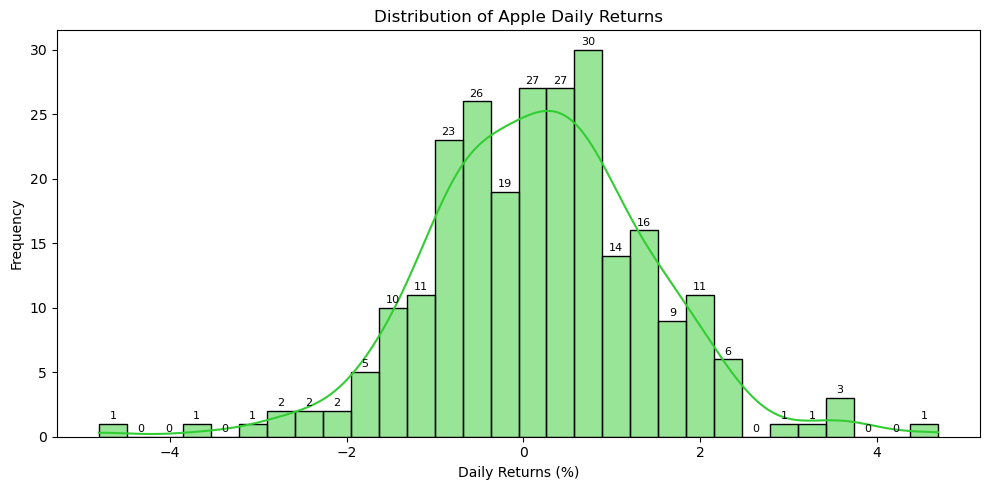

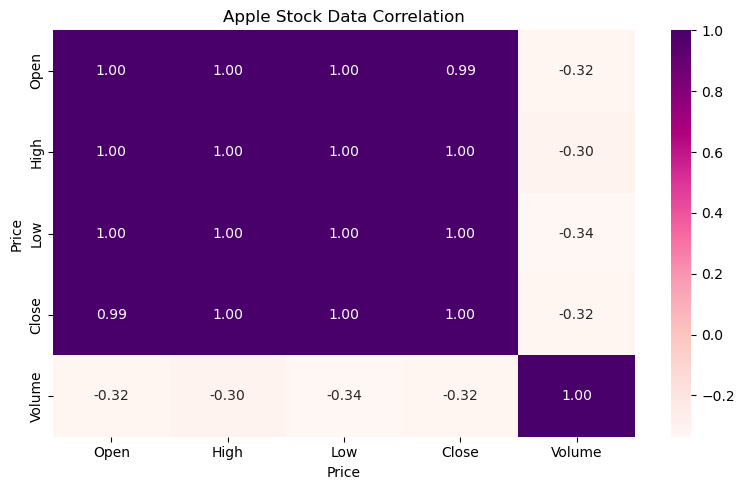

Company: Apple Inc.
Ticker Symbol: AAPL
Period: January to December 2023
Average Closing Price: $170.05
Highest Closing Price: $195.72
Lowest Closing Price: $122.83
Avereage Trading Volume: 59,223,548
Average Daily Returns: 0.1835%
Price Change Over Period: 54.80%


In [ ]:
import yfinance as yf 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = yf.download("AAPL",start="2023-01-01",end="2023-12-31")
if isinstance(data.columns,pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

print("====== Apple Stock Market Data ======")
print(data.head())

print("====== Dataset Information ======")
print(data.info())

print("====== Missing Values ======")
print(data.isnull().sum())

data.to_csv("AAPL_Stock_Data.csv")
print("Data saved successfully as AAPL_Stock_Data.csv")

# 20 day and 50 day moving averages

data["MA20"] = data["Close"].rolling(window=20).mean()
data["MA50"] = data["Close"].rolling(window=50).mean()

data["Price Change"] = data["Close"].diff()

data["Daily Return"] = data["Close"].pct_change() * 100

closing_prices = data["Close"].to_numpy()

print("Average Closing Price:",np.mean(closing_prices))
print("Maximum Closing Price:",np.max(closing_prices))
print("Minimum Closing Price:",np.min(closing_prices))
print("Standatd Deviation:",np.std(closing_prices))

# Highest and lowest closing prices
print("====== Highest Closing Price ======")
print(data["Close"].idxmax(),data["Close"].max())

print("====== Lowest Closing Price ======")
print(data["Close"].idxmin(),data["Close"].min())

print("====== Analyzed Stock Data ======")
print(data.tail())

# Filter days when closing price was above $180
high_price = data[data["Close"] > 180]
print("====== Days when closing price was above $180 ======")
print(high_price[["Close","Volume"]])

#Sort data by closing price from highest to lowest
sorted_data = data.sort_values(by="Close",ascending=False)

print("====== Top 10 Highest Closing Prices ======")
print(sorted_data[["Close","Volume"]].head(10))

# days with trading volume above average
average_volume = data["Volume"].mean()

high_volume = data[data["Volume"] > average_volume]
print("====== Days with Above-Average Trading Volume ======")
print(high_volume[["Close","Volume"]])

# Visualization of Apple Stock market trends
# Visualization1: Apple closing price

plt.figure(figsize=(12,5))
plt.plot(data.index,data["Close"],label="Closing Price",color = "green")
plt.title("Apple Stock Closing Price - 2023")
plt.xlabel("Data")
plt.ylabel("Price(USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Visualization2: Closing price with moving averages

plt.figure(figsize=(12,5))
plt.plot(data.index,data["Close"],label="Closing Price",color = "forestgreen")
plt.plot(data.index,data["MA20"],label="20-Day Moving Average",color = "limegreen")
plt.plot(data.index,data["MA50"],label="50-Day Moving Average",color = "lightgreen")

plt.title("Apple Stock Price and Moving Averages")
plt.xlabel("Data")
plt.ylabel("Price(USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Visualization3: Trading Volume
plt.figure(figsize=(12,5))
plt.bar(data.index,data["Volume"],color = "limegreen")
plt.title("Apple Stock Trading Volume - 2023")
plt.xlabel("Data")
plt.ylabel("Trading Volume")
plt.tight_layout()
plt.show() 

# Visualization4: Daily stock returns
plt.figure(figsize=(10,5))
ax = sns.histplot(data["Daily Return"].dropna(),bins=30,kde=True,color="limegreen")
for container in ax.containers:
    ax.bar_label(container, fontsize=8, padding=2)
plt.title("Distribution of Apple Daily Returns")
plt.xlabel("Daily Returns (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Visualization5: Correlation heatmap
plt.figure(figsize=(8,5))
correlation = data[["Open","High","Low","Close","Volume"]].corr()

sns.heatmap(correlation,annot=True,cmap="RdPu",fmt=".2f")
plt.title("Apple Stock Data Correlation")
plt.tight_layout()
plt.show()

# Stock Summary
print("=" * 30)
print("Company: Apple Inc.")
print("Ticker Symbol: AAPL")
print("Period: January to December 2023")

print(f"Average Closing Price: ${data['Close'].mean():.2f}")
print(f"Highest Closing Price: ${data['Close'].max():.2f}")
print(f"Lowest Closing Price: ${data['Close'].min():.2f}")
print(f"Avereage Trading Volume: {data['Volume'].mean():,.0f}")
print(f"Average Daily Returns: {data['Daily Return'].mean():.4f}%")

first_price = data["Close"].iloc[0]
last_price = data["Close"].iloc[-1]

price_change = ((last_price - first_price) / first_price) * 100
print(f"Price Change Over Period: {price_change:.2f}%")
print("=" * 30)